In [1]:
import shapefile
import overpy
from shapely.geometry.polygon import LinearRing, Polygon, LineString, Point
from shapely.geometry import MultiPolygon
import pandas as pd
from area import area
import dill
import numpy as np

In [2]:
def getArea(poly):

    if(poly.geom_type == 'Polygon'):

        pnt_list = polyToPointList(poly)
        lst = []
        lst.append(pnt_list)
        area_obj = {'type': 'Polygon', 'coordinates': lst}
        for key in area_obj.keys():
            if(key == 'coordinates'):
                for i, v in enumerate(area_obj[key][0]):
                    area_obj[key][0][i] = [
                        float(
                            area_obj[key][0][i][0]), float(
                            area_obj[key][0][i][1])]
        return area(area_obj)
    elif(poly.geom_type == 'MultiPolygon'):
        res = 0
        for poly_ in poly:
            pnt_list = polyToPointList(poly_)
            lst = []
            lst.append(pnt_list)
            area_obj = {'type': 'Polygon', 'coordinates': lst}
            for key in area_obj.keys():
                if(key == 'coordinates'):
                    for i, v in enumerate(area_obj[key][0]):
                        area_obj[key][0][i] = [
                            float(
                                area_obj[key][0][i][0]), float(
                                area_obj[key][0][i][1])]
            res = res + area(area_obj)

        return res
    
"""    
def overpyClutter(poly):
    api = overpy.Overpass()
    x, y = poly.exterior.xy
    bbox = min(y), min(x), max(y), max(x)
    overpy_clutter = api.query('way' + str(bbox) + ';  (._;>;);out body;')
    return overpy_clutter
""" 
def overpyClutter(poly):
    api = overpy.Overpass()
    x, y = poly.exterior.xy
    bbox = min(y), min(x), max(y), max(x)
    qrty_str='('+'way' + str(bbox)+';'+'node' + str(bbox)+';'+'rel' + str(bbox)+';'+ ');(._;>;);out body;'
    #qrty_str='('+'way' + str(bbox)+';'+ ');(._;>;);out body;'
    print(qrty_str)
    overpy_clutter = api.query(qrty_str)
    return overpy_clutter

def getclutter(overpy_clutter, o_poly):

    #api = overpy.Overpass()
    o_poly = Polygon([[i[0], i[1]] for i in list(o_poly.exterior.coords)])
    #result = api.query('way'+str(bbox)+';  (._;>;);out body;')
    # o_poly=Polygon([[77.689781,12.984666],[77.696791,12.984666],[77.696791,12.990562],[77.689781,12.990562]])
    DEFAULT_DICT = {
        'id': 'id',
        'type_0': None,
        'type_1': None,
        'type_2': None,
        'geometry_points': None,
        'geometry': None,
        'building': None,
        'building:levels': None,
        'height': None,
        'area(sqm)': None,
        'length(m)': None,
        'landuse': None,
        'amenity': None,
        'leisure': None,
        'public_transport': None,
        'railway': None,
        'highway': None,
        'bridge': None,
        'traffic:hourly': None,
        'landcover': None,
        'natural': None,
        'route_master': None,
        'type_0': None,
        'type_1': None,
        'type_2': None}
    dict_list = [DEFAULT_DICT.copy()]

    for i, way in enumerate(overpy_clutter.ways):
        temp_dict = DEFAULT_DICT.copy()

        if(bool(way.tags) and (pd.isna(way.tags.get("building")) == False or
                               way.tags.get("landuse") == 'residential')):
            temp_dict['id'] = i
            if(len(way.nodes) > 0):

                temp_dict['geometry_points'] = [
                    (float(node.lon), float(node.lat)) for node in way.nodes]

                if(len(temp_dict['geometry_points']) > 0):

                    if(o_poly.intersects(Polygon(temp_dict['geometry_points']))):

                        temp_dict['height'] = way.tags.get("height")
                        temp_dict['building'] = way.tags.get("building")
                        temp_dict['building:levels'] = way.tags.get(
                            "building:levels")
                        temp_dict['landuse'] = way.tags.get("landuse")
                        temp_dict['amenity'] = way.tags.get("amenity")
                        temp_dict['leisure'] = way.tags.get("leisure")
                        temp_dict['public_transport'] = way.tags.get(
                            "public_transport")
                        temp_dict['highway'] = way.tags.get("highway")
                        temp_dict['bridge'] = way.tags.get("bridge")
                        temp_dict['historic'] = way.tags.get("historic")
                        temp_dict['traffic:hourly'] = way.tags.get(
                            "traffic:hourly")
                        temp_dict['landcover'] = way.tags.get("landcover")
                        temp_dict['natural'] = way.tags.get("natural")
                        temp_dict['route_master'] = way.tags.get(
                            "route_master")
                        temp_dict['railway'] = way.tags.get("railway")

                        filter_pt_lst = []
                        if(pd.isna(temp_dict['building']) == False):

                            temp_dict['geometry'] = o_poly.intersection(
                                Polygon(temp_dict['geometry_points']))
                            # print(temp_dict['geometry'])
                            building_area = 0
                            if temp_dict['geometry'].geom_type == 'Polygon':
                                building_area = getArea(temp_dict['geometry'])
                            elif temp_dict['geometry'].geom_type == 'MultiPolygon':
                                for sub_poly in temp_dict['geometry']:
                                    building_area += getArea(sub_poly)

                            temp_dict['type_0'] = 'Building'
                            temp_dict['type_1'] = 'Building'
                            temp_dict['type_2'] = way.tags
                            temp_dict['area(sqm)'] = building_area
                            temp_dict['length(m)'] = 0

                        elif(pd.isna(temp_dict['landuse']) == False and temp_dict['landuse'] == 'residential'):

                            temp_dict['geometry'] = o_poly.intersection(
                                Polygon(temp_dict['geometry_points']))
                            building_area = 0
                            if temp_dict['geometry'].geom_type == 'Polygon':
                                building_area = getArea(temp_dict['geometry'])
                            elif temp_dict['geometry'].geom_type == 'MultiPolygon':
                                for sub_poly in temp_dict['geometry']:
                                    building_area += getArea(sub_poly)

                            temp_dict['type_0'] = 'Building'
                            temp_dict['type_1'] = 'Building'
                            temp_dict['type_2'] = way.tags
                            temp_dict['area(sqm)'] = building_area
                            temp_dict['length(m)'] = 0

                        dict_list.append(temp_dict)

    node_data = pd.DataFrame(dict_list)

    return node_data

In [3]:
def point_in_poly(poly, point_lat, point_lon):

    point_chk = Point(point_lon, point_lat)
    if(point_chk.within(poly)):
        return 1
    else:
        return 0
    
def polyToPointList(poly):
    pnt_list = []
    x, y = poly.exterior.xy
    for i, x_ in enumerate(x):
        pnt_list.append([x[i], y[i]])
    return pnt_list


def lineToPointList(line_):
    pnt_list = []
    if(line_.geom_type == 'MultiLineString'):
        for it in line_:
            x, y = it.xy
            for i, x_ in enumerate(x):
                pnt_list.append([x[i], y[i]])
    else:
        x, y = line_.xy
        for i, x_ in enumerate(x):
            pnt_list.append([x[i], y[i]])
    return pnt_list


def getRouteLen(ptlist):
    x, y = [i[0] for i in ptlist], [i[1] for i in ptlist]
    len_ = 0
    j = 0
    for i, x_ in enumerate(x):
        if(i <= len(x) - 2):
            len_ = len_ + \
                great_circle((y[i], x[i]), (y[i + 1], x[i + 1])).meters

    return round(len_, 3)

In [4]:
path='C:/Users/esurmon/Downloads/DTAC_QGIS_PROJ/Smaller/gadm36_THA_2_CC2_4406_WGS84.shp'
sf = shapefile.Reader(path)
for shaperec in sf.iterShapeRecords():
    
    bound_region=Polygon((shaperec.shape.points))

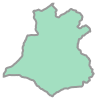

In [5]:
bound_region

In [12]:
path='C:/Users/esurmon/Downloads/DTAC_QGIS_PROJ/Smaller/GRID_INFO_ADDED.shp'
path_fout='C:/Users/esurmon/Downloads/DTAC_QGIS_PROJ/Smaller/GRID_INFO_ADDED_V11_50.shp'

In [13]:
sf = shapefile.Reader(path)
sf.fields[1:]

[['id', 'N', 20, 0],
 ['left', 'N', 24, 15],
 ['top', 'N', 24, 15],
 ['right', 'N', 24, 15],
 ['bottom', 'N', 24, 15],
 ['CNTBLDNG', 'N', 24, 15],
 ['AREABLDNGS', 'N', 24, 15],
 ['BLDNG_PER', 'N', 11, 3]]

In [14]:

w = shapefile.Writer(path_fout)
w.shapeType = 5

fields = sf.fields[1:]
"""
fields.append(['CNTBLDNG', 'N', 24, 15])
fields.append(['AREABLDNGSQM', 'N', 24, 15])
fields.append(['CNTAMENITY', 'N', 24, 15])
"""
fields.append(['BUILD_PROB', 'N', 24, 15])
fields.append(['CENTER_LAT', 'N', 24, 15])
fields.append(['CENTER_LON', 'N', 24, 15])


w.fields=fields

In [15]:
w.fields

[['id', 'N', 20, 0],
 ['left', 'N', 24, 15],
 ['top', 'N', 24, 15],
 ['right', 'N', 24, 15],
 ['bottom', 'N', 24, 15],
 ['CNTBLDNG', 'N', 24, 15],
 ['AREABLDNGS', 'N', 24, 15],
 ['BLDNG_PER', 'N', 11, 3],
 ['BUILD_PROB', 'N', 24, 15],
 ['CENTER_LAT', 'N', 24, 15],
 ['CENTER_LON', 'N', 24, 15]]

In [16]:
data=pd.read_csv('geotiff/combined_100_50_V11.txt',sep='\t')

i=0

for shaperec in sf.iterShapeRecords():
    
    if(pd.isna(shaperec.record[0])==False):
        
        COUNT_BUILDING = 0
        AREA_BUILDING_SQM = 0 
        AMENITY_COUNT=0
        BUILD_PROB=0

        grid_polygon=Polygon((shaperec.shape.points))
        grid_polygon_centroid=grid_polygon.centroid

        in_region=point_in_poly(bound_region, grid_polygon.centroid.y, grid_polygon.centroid.x)
        CENTER_LAT=grid_polygon.centroid.y
        CENTER_LON=grid_polygon.centroid.x
        
        intersect_flag=bound_region.intersects(grid_polygon)

        if(in_region==1 or intersect_flag==True):

            COUNT_BUILDING = 0
            AREA_BUILDING_SQM = 0
            AMENITY_COUNT=0
            BUILD_PROB=0
            

            try:
                
                if(shaperec.record[0] in data['GRID_ID'].tolist()):
                    BUILD_PROB=data.loc[data['GRID_ID']==shaperec.record[0]]['BLDNG_PROB_GTE_0.5'].values[0]
                else:
                    BUILD_PROB=0
                    print("Grid image not found for => {}".format(str(shaperec.record[0])))

                    
    

            except Exception as e:

                print(e)
        

            print(shaperec.record[0],BUILD_PROB,CENTER_LAT,CENTER_LON)
                
            w.record(*shaperec.record,BUILD_PROB,CENTER_LAT,CENTER_LON)
            w.shape(shaperec.shape)   

55 0.0 15.92352420475 102.94777074225001
56 1.0 15.919019700249999 102.94777074225001
57 0.0 15.914515195749999 102.94777074225001
58 0.0 15.91001069125 102.94777074225001
126 0.0 15.93703771825 102.95227524675
127 0.0 15.93253321375 102.95227524675
128 1.0 15.92802870925 102.95227524675
129 0.0 15.92352420475 102.95227524675
130 0.0 15.919019700249999 102.95227524675
131 0.0 15.914515195749999 102.95227524675
132 0.0 15.91001069125 102.95227524675
199 20.0 15.941542222749998 102.95677975125
200 2.0 15.93703771825 102.95677975125
201 0.0 15.93253321375 102.95677975125
202 1.0 15.92802870925 102.95677975125
203 0.0 15.92352420475 102.95677975125
204 0.0 15.919019700249999 102.95677975125
205 0.0 15.914515195749999 102.95677975125
206 1.0 15.91001069125 102.95677975125
273 4.0 15.941542222749998 102.96128425575
274 6.0 15.93703771825 102.96128425575
275 0.0 15.93253321375 102.96128425575
276 0.0 15.92802870925 102.96128425575
277 0.0 15.92352420475 102.96128425575
278 0.0 15.919019700249

In [17]:
w.close()